In [47]:
def plot_metrics(weights_stats_df_full):

    import matplotlib.pyplot as plt

    sizze = 17

    # Для каждого показателя построим график: среднее (линия) и коридор min-max (заливка)

    metrics = [
        ("Recall", "Recall_mean", "Recall_min", "Recall_max"),
        ("Precision", "Precision_mean", "Precision_min", "Precision_max"),
        ("F1 Score", "F1_mean", "F1_min", "F1_max"),
        ("Time, ms", "Time_mean_ms", "Time_min_ms", "Time_max_ms"),
    ]

    fig, axes = plt.subplots(4, 1, figsize=(14, 20))

    # Подписи для оси X — тройки весов
    weight_labels = weights_stats_df_full.apply(
        lambda row: f"({int(row['w1'])},{int(row['w2'])},{int(row['w3'])})", axis=1)

    x = range(len(weights_stats_df_full))

    # Подписи только каждый 3й, остальные — пустые строки
    xtick_labels = [
        weight_labels[i] if i % 3 == 0 else "" 
        for i in x
    ]

    for ax, (title, mean_col, min_col, max_col) in zip(axes, metrics):
        mean = weights_stats_df_full[mean_col]
        min_ = weights_stats_df_full[min_col]
        max_ = weights_stats_df_full[max_col]

        ax.plot(x, mean, label=f"{title} (mean)", color='b')
        ax.fill_between(x, min_, max_, color='b', alpha=0.2, label=f"{title} min-max corridor")

        # Добавляем красную точку с максимальным средним значением
        max_mean_idx = mean.idxmax()
        ax.plot(
            max_mean_idx,
            mean[max_mean_idx],
            'ro',
            markersize=8,
            label=f"Максимум {title} mean"
        )

        # Все подписи делаем размером как заголовок (fontsize=20)
        ax.set_xlabel("Веса (w1, w2, w3)", fontsize=sizze)
        ax.set_ylabel(title, fontsize=sizze)
        ax.set_title(f"{title}: mean and min-max corridor", fontsize=sizze)  # Увеличили шрифт
        ax.legend(fontsize=sizze)
        ax.grid(True)
        # Показываем тройки весов на оси x — только каждый 50-й
        ax.set_xticks(x)
        ax.set_xticklabels(xtick_labels, rotation=90, fontsize=10)

    plt.tight_layout()
    plt.show()

In [34]:
import os
import pandas as pd

data_folder = "data_m10/saves"
datasets = {}

for fname in os.listdir(data_folder):
    fpath = os.path.join(data_folder, fname)
    if os.path.isfile(fpath):
        try:
            # Try to read as CSV, fallback to Excel
            if fname.lower().endswith(('.csv', '.tsv')):
                datasets[fname] = pd.read_csv(fpath)
            elif fname.lower().endswith(('.xlsx', '.xls')):
                datasets[fname] = pd.read_excel(fpath)
            else:
                # Optionally handle other formats/skipped files here
                pass
        except Exception as e:
            print(f"Could not read file {fname}: {e}")

# Теперь datasets содержит ключи - имена файлов, значения - считанные датафреймы
# datasets

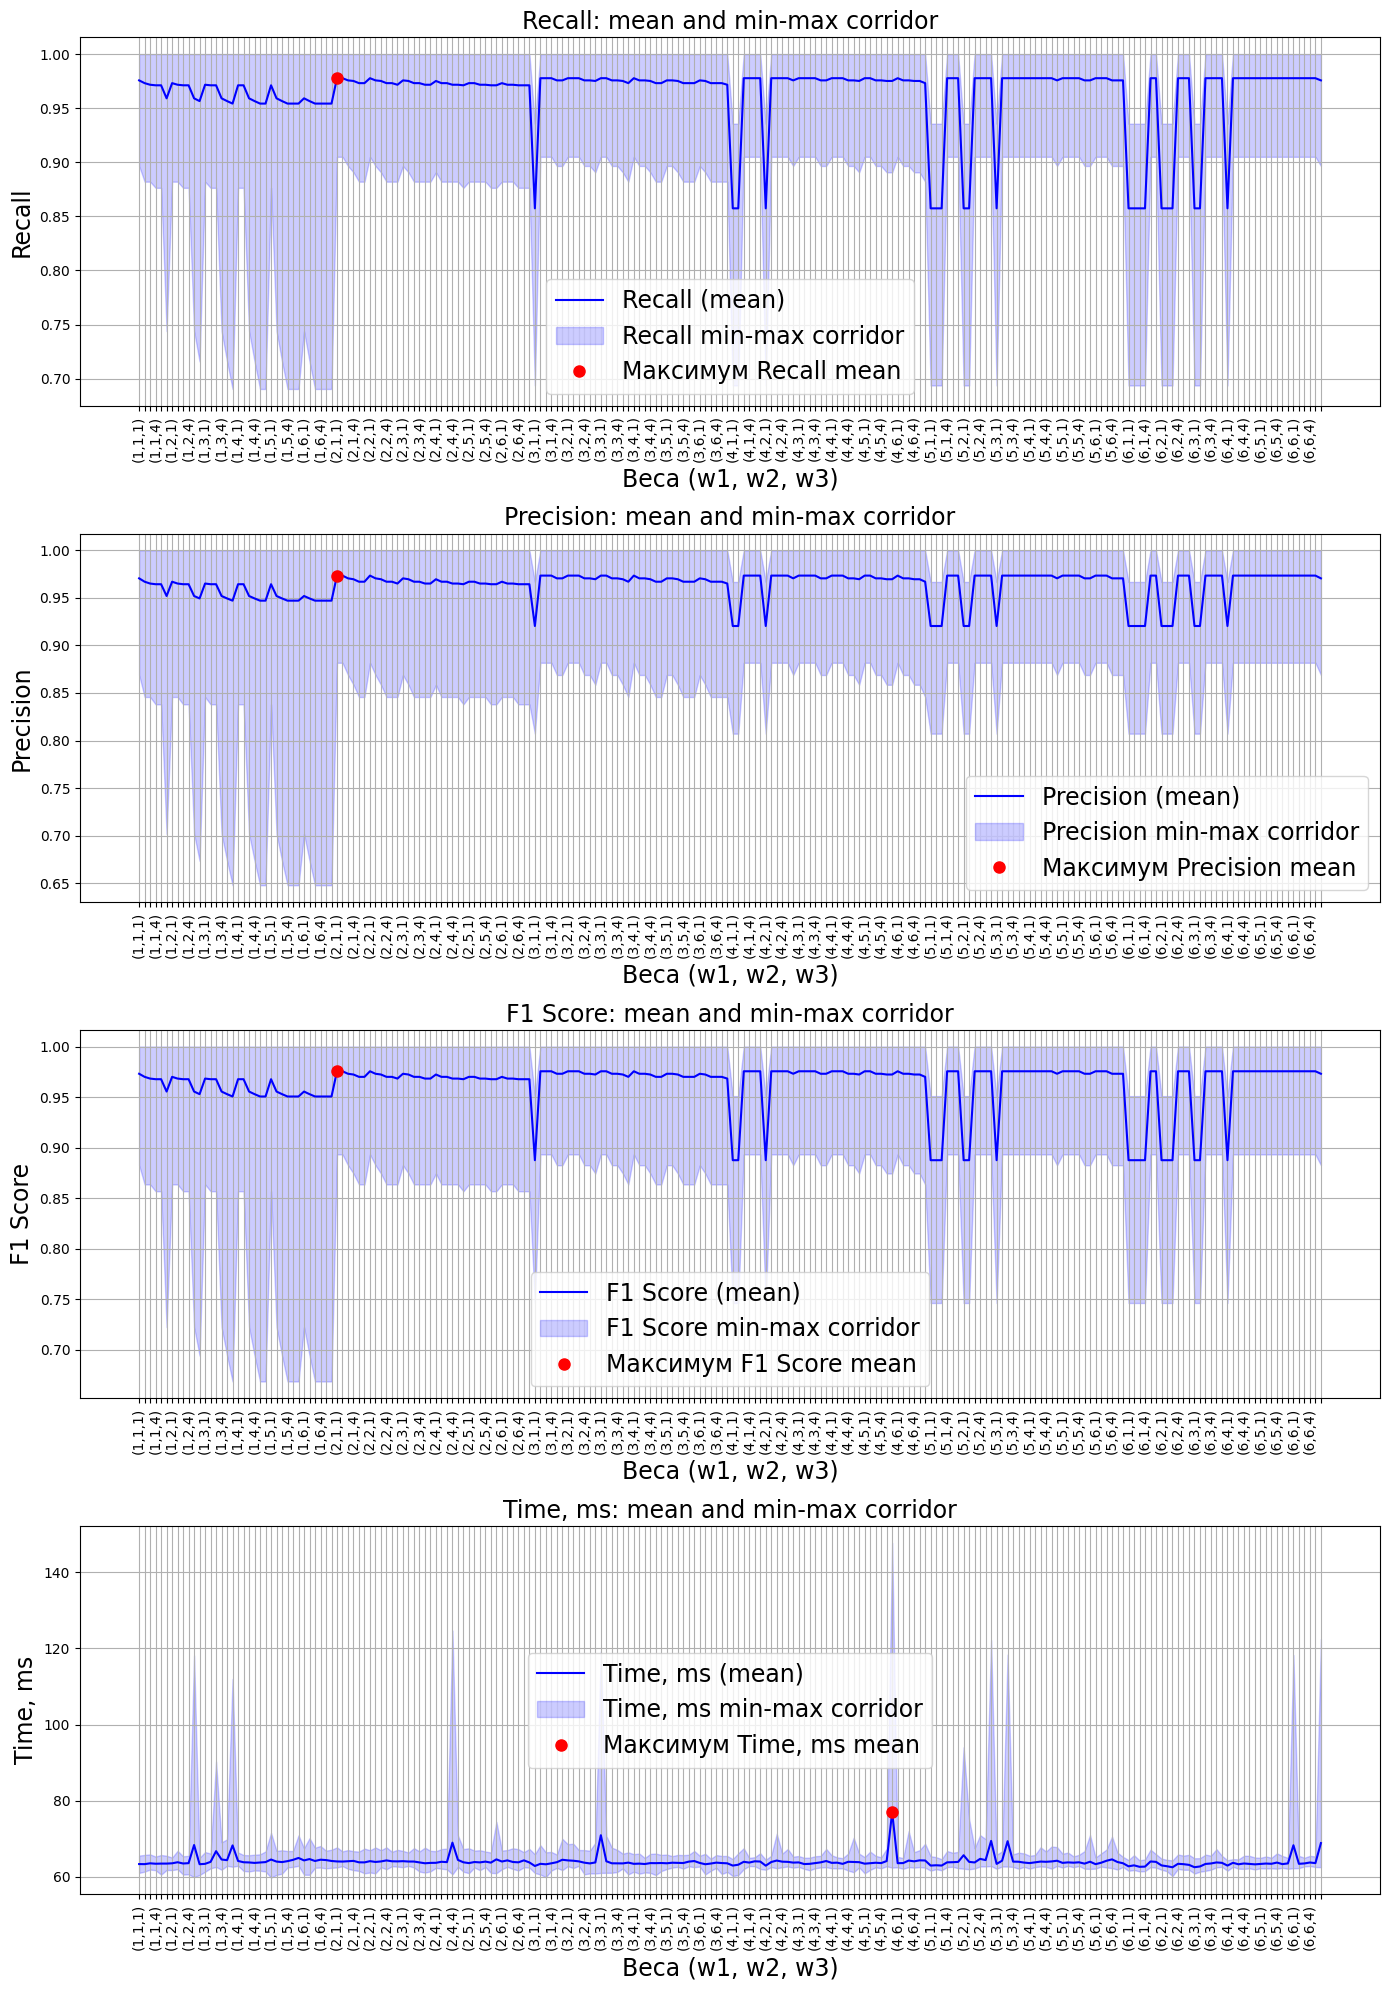

In [50]:
plot_metrics(datasets['weights_stats_df_full_df_lev.xlsx'])

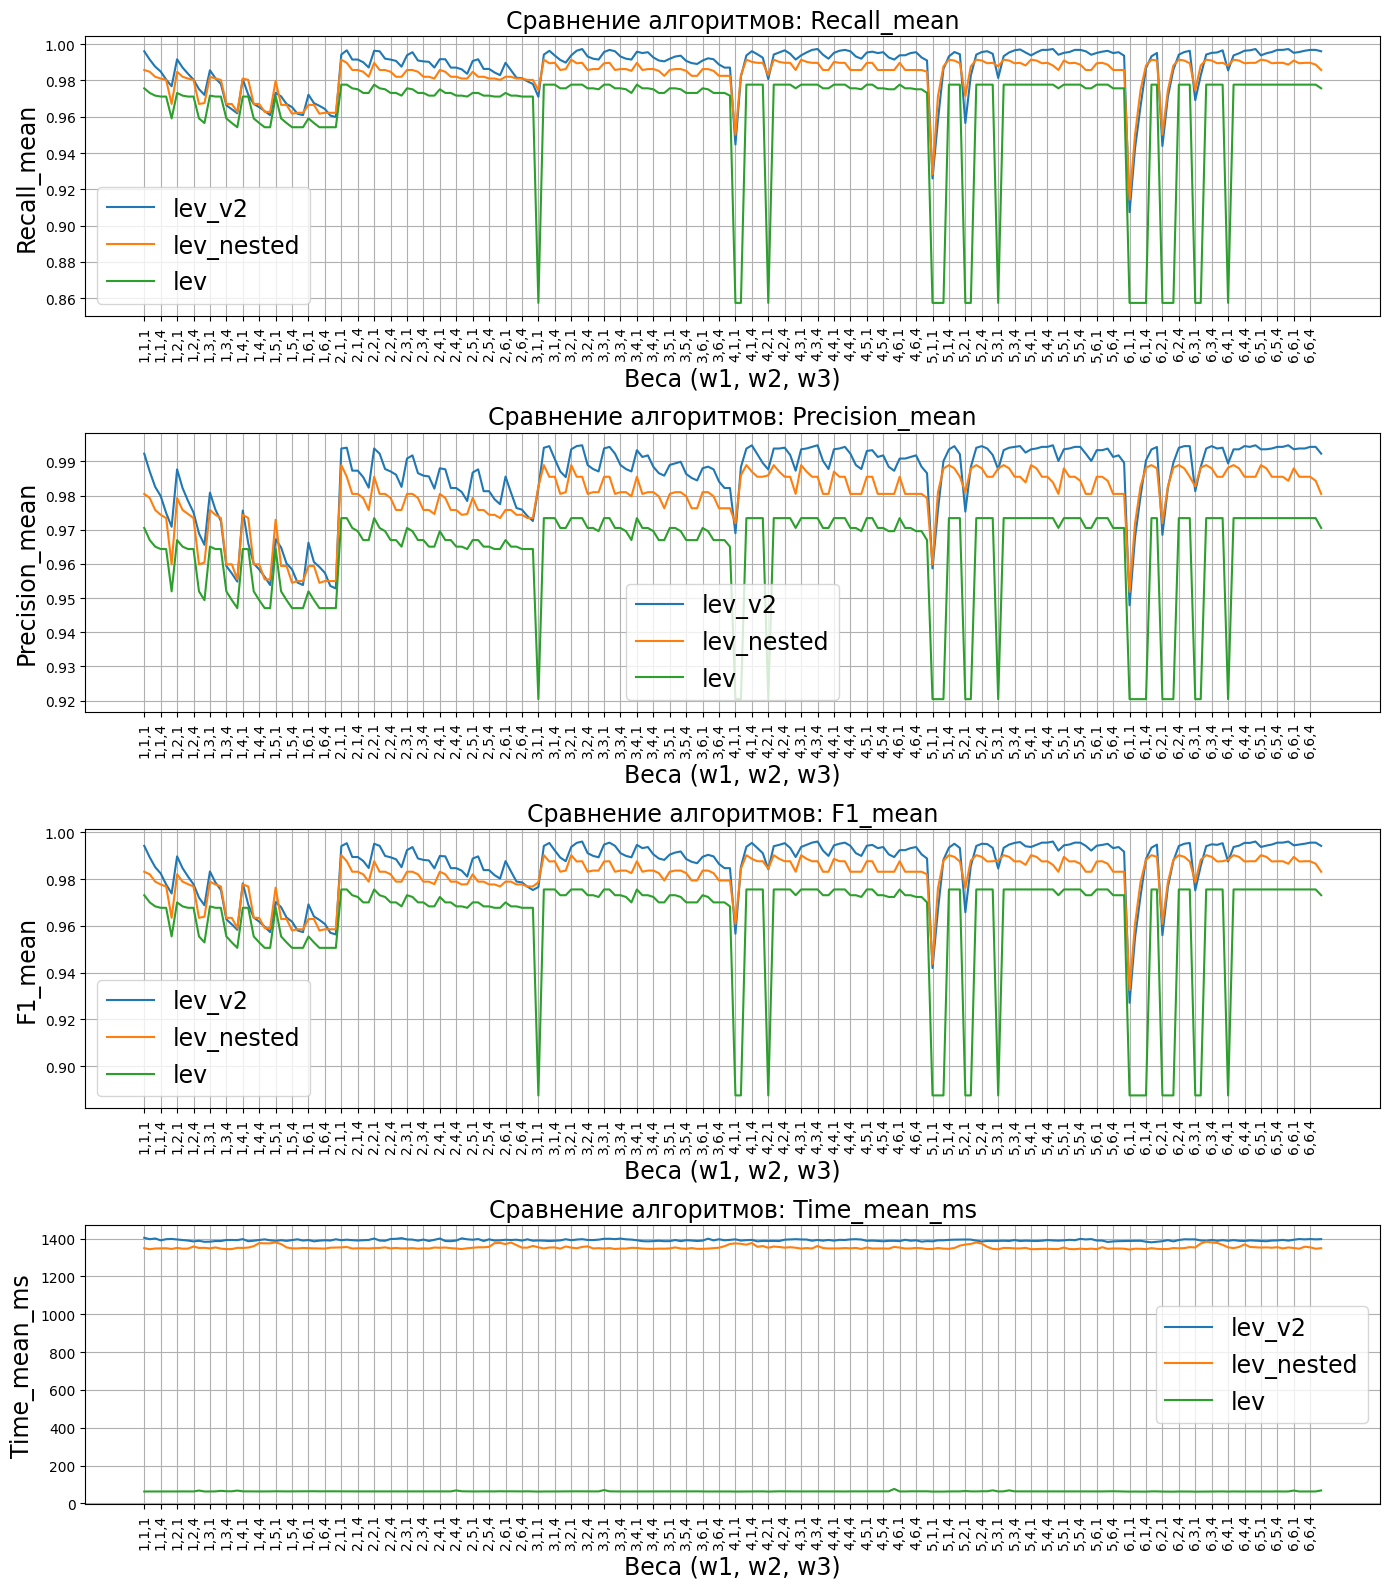

In [51]:
import matplotlib.pyplot as plt

def plot_algorithms_metrics(datasets, algorithm_names, metrics):
    """
    Строит графики сравнения заданных метрик для нескольких алгоритмов (датасетов).
    Каждая линия на графике — это отдельный алгоритм с его весами для соответствующей метрики.
    
    datasets: список датафреймов (weights_stats_df_full_df_lev, weights_stats_df_full_df_lev_v2, ...)
    algorithm_names: список названий алгоритмов (['lev', 'lev_v2', ...])
    metrics: список метрик, которые надо построить (['Recall_mean', 'Precision_mean', ...])
    """
    x_labels = []
    for ds in datasets:
        triples = ds[['w1', 'w2', 'w3']].astype(str).agg(','.join, axis=1)
        x_labels.append(triples.values)
    
    x = [range(len(labels)) for labels in x_labels]
    num_metrics = len(metrics)
    plt.figure(figsize=(14, 4 * num_metrics))
    
    label_fontsize = 17
    tick_fontsize = 10
    
    for idx, metric in enumerate(metrics):
        plt.subplot(num_metrics, 1, idx + 1)
        for i, ds in enumerate(datasets):
            plt.plot(x[i], ds[metric], label=algorithm_names[i])
        # x ticks: делать подписи только каждые 3 шага
        tick_indices = list(range(0, len(x_labels[0]), 3))
        tick_labels = [x_labels[0][i] for i in tick_indices]
        plt.xticks(tick_indices, tick_labels, rotation=90, fontsize=tick_fontsize)
        plt.xlabel("Веса (w1, w2, w3)", fontsize=label_fontsize)
        plt.ylabel(metric, fontsize=label_fontsize)
        plt.title(f"Сравнение алгоритмов: {metric}", fontsize=label_fontsize)
        plt.legend(fontsize=label_fontsize)
        plt.grid(True)
    plt.tight_layout()
    plt.show()

datasets_list = [datasets['weights_stats_df_full_df_lev_v2.xlsx'], datasets['weights_stats_df_full_df_lev_nested.xlsx'], datasets['weights_stats_df_full_df_lev.xlsx']]
algorithm_names = ['lev_v2', 'lev_nested', 'lev']
metrics = ['Recall_mean', 'Precision_mean', 'F1_mean', 'Time_mean_ms']
plot_algorithms_metrics(datasets_list, algorithm_names, metrics)